# Notebook 1: Data Audit
**Goal:** Check the quality of the DataCo supply chain data before running any analysis or forecasting.
**Data:** 180,519 order items across 65,752 orders, January 2015 to January 2018, stored in SQL Server (`supply_chain` database).

In [16]:
%pip install sqlalchemy pyodbc

Note: you may need to restart the kernel to use updated packages.


In [17]:
import pandas as pd
from sqlalchemy import create_engine

engine = create_engine(
    "mssql+pyodbc://localhost\\SQLEXPRESS/supply_chain"
    "?driver=ODBC+Driver+17+for+SQL+Server&trusted_connection=yes&TrustServerCertificate=yes"
)

pd.read_sql("SELECT COUNT(*) AS n FROM order_items", engine)

,n
0,180519


## 2. Connect to SQL Server
Connected Python to the `supply_chain` database with SQLAlchemy. The row count of `order_items` is 180,519, which matches the CSV, so the SQL load was complete.

In [18]:
query = """
SELECT oi.*, o.Order_Date, o.Shipping_Date, o.Shipping_Mode, o.Delivery_Status,
       o.Late_Delivery_Risk, o.Days_Shipping_Real, o.Days_Shipping_Scheduled,
       o.Market, o.Order_Region, o.Order_Status
FROM order_items oi
JOIN orders o ON oi.Order_Id = o.Order_Id
"""
df_sql = pd.read_sql(query, engine)
print(df_sql.shape)
df_sql.head()

(180519, 21)


,Order_Item_Id,Order_Id,Product_Card_Id,Quantity,Unit_Price,Discount,Discount_Rate,Sales,Item_Total,Profit,...,Order_Date,Shipping_Date,Shipping_Mode,Delivery_Status,Late_Delivery_Risk,Days_Shipping_Real,Days_Shipping_Scheduled,Market,Order_Region,Order_Status
0,1,1,957,1,299.98,60.0,0.20,299.98,239.98,88.79,...,2015-01-01 00:00:00,2015-01-03 00:00:00,Standard Class,Advance shipping,False,2,4,LATAM,Central America,CLOSED
1,2,2,1073,1,199.99,6.0,0.03,199.99,193.99,91.18,...,2015-01-01 00:21:00,2015-01-04 00:21:00,Standard Class,Advance shipping,False,3,4,LATAM,South America,PENDING_PAYMENT
2,3,2,502,5,50.00,22.5,0.09,250.00,227.50,68.25,...,2015-01-01 00:21:00,2015-01-04 00:21:00,Standard Class,Advance shipping,False,3,4,LATAM,South America,PENDING_PAYMENT
3,4,2,403,1,129.99,22.1,0.17,129.99,107.89,36.47,...,2015-01-01 00:21:00,2015-01-04 00:21:00,Standard Class,Advance shipping,False,3,4,LATAM,South America,PENDING_PAYMENT
4,5,4,897,2,24.99,9.0,0.18,49.98,40.98,4.10,...,2015-01-01 01:03:00,2015-01-06 01:03:00,Standard Class,Late delivery,True,5,4,LATAM,South America,CLOSED


Joined `order_items` and `orders` in SQL and loaded the result into one DataFrame (`df_sql`). The row count is unchanged at 180,519, so the join did not duplicate or drop rows. The rest of the audit uses this DataFrame.

In [19]:
print("Duplicate order items:", df_sql["Order_Item_Id"].duplicated().sum())
print("Fully duplicated rows:", df_sql.duplicated().sum())

Duplicate order items: 0
Fully duplicated rows: 0


## 3. Duplicates
No duplicate order item IDs and no fully duplicated rows.

In [20]:
df_sql["Order_Date"] = pd.to_datetime(df_sql["Order_Date"])
df_sql["Shipping_Date"] = pd.to_datetime(df_sql["Shipping_Date"])

print("Date range:", df_sql["Order_Date"].min(), "to", df_sql["Order_Date"].max())
print("Shipped before ordered:", (df_sql["Shipping_Date"] < df_sql["Order_Date"]).sum())

calc_days = (df_sql["Shipping_Date"].dt.normalize() - df_sql["Order_Date"].dt.normalize()).dt.days
print("Real shipping days match calculated:", (calc_days == df_sql["Days_Shipping_Real"]).mean())

Date range: 2015-01-01 00:00:00 to 2018-01-31 23:38:00
Shipped before ordered: 0
Real shipping days match calculated: 1.0


## 4. Dates
Orders run from January 1, 2015 to January 31, 2018. No order shipped before it was placed. Shipping days calculated from the two dates match the `Days_Shipping_Real` column on every row, so that column is reliable.

In [21]:
print("Quantity <= 0:", (df_sql["Quantity"] <= 0).sum())
print("Unit price <= 0:", (df_sql["Unit_Price"] <= 0).sum())
print("Discount rate range:", df_sql["Discount_Rate"].min(), "to", df_sql["Discount_Rate"].max())
print("Sales != price x quantity:", ((df_sql["Sales"] - df_sql["Unit_Price"] * df_sql["Quantity"]).abs() > 0.01).sum())

print(pd.crosstab(df_sql["Delivery_Status"], df_sql["Late_Delivery_Risk"]))
print(pd.crosstab(df_sql["Order_Status"] == "CANCELED", df_sql["Delivery_Status"] == "Shipping canceled"))

Quantity <= 0: 0
Unit price <= 0: 0
Discount rate range: 0.0 to 0.25
Sales != price x quantity: 0
Late_Delivery_Risk  False  True 
Delivery_Status                 
Advance shipping    41592      0
Late delivery           0  98977
Shipping canceled    7754      0
Shipping on time    32196      0
Delivery_Status   False  True 
Order_Status                  
False            172765   4062
True                  0   3692


## 5. Value checks
No zero or negative quantities or prices, discount rates stay between 0 and 0.25, and `Sales` equals unit price × quantity on every row.

**Finding 1: `Late_Delivery_Risk` leaks the answer.** Every "Late delivery" row has the flag set to 1, and every other status has it set to 0. If I model lateness, `Delivery_Status` and the real shipping days must be excluded, or the model will look perfect without learning anything.

**Finding 2: "Shipping canceled" mixes two statuses.** Of its 7,754 rows, 3,692 are `CANCELED` orders and the remaining 4,062 match the count of `SUSPECTED_FRAUD` orders. These rows are all marked "not late," so they should be excluded or handled separately in the lateness model.

In [22]:
import matplotlib.pyplot as plt

df_sql["Month"] = df_sql["Order_Date"].dt.to_period("M")
monthly = df_sql.groupby("Month").agg(
    Items=("Order_Item_Id", "size"),
    Orders=("Order_Id", "nunique"),
    Products=("Product_Card_Id", "nunique"),
    Sales=("Sales", "sum"),
)
monthly["Items_per_Order"] = monthly["Items"] / monthly["Orders"]
monthly.index = monthly.index.to_timestamp()

monthly.tail(8)

,Items,Orders,Products,Sales,Items_per_Order
Month,,,,,
2017-06-01,4951,1676,42,1032086.47,2.954057
2017-07-01,5318,1776,42,1104373.34,2.994369
2017-08-01,5305,1768,42,1109337.15,3.000566
2017-09-01,5189,1723,53,1143775.09,3.011608
2017-10-01,2255,2101,20,1073994.16,1.073298
2017-11-01,2055,2055,8,626914.37,1.000000
2017-12-01,2124,2124,14,503910.81,1.000000
2018-01-01,2123,2123,10,331650.11,1.000000


## 6. Structure over time
Monthly data is stable through September 2017: about 3.0 items per order and 42 to 54 distinct products per month. From October 2017 it changes. Orders stay at about 2,100 a month, but each order has exactly one item, and only 8 to 20 products are sold.

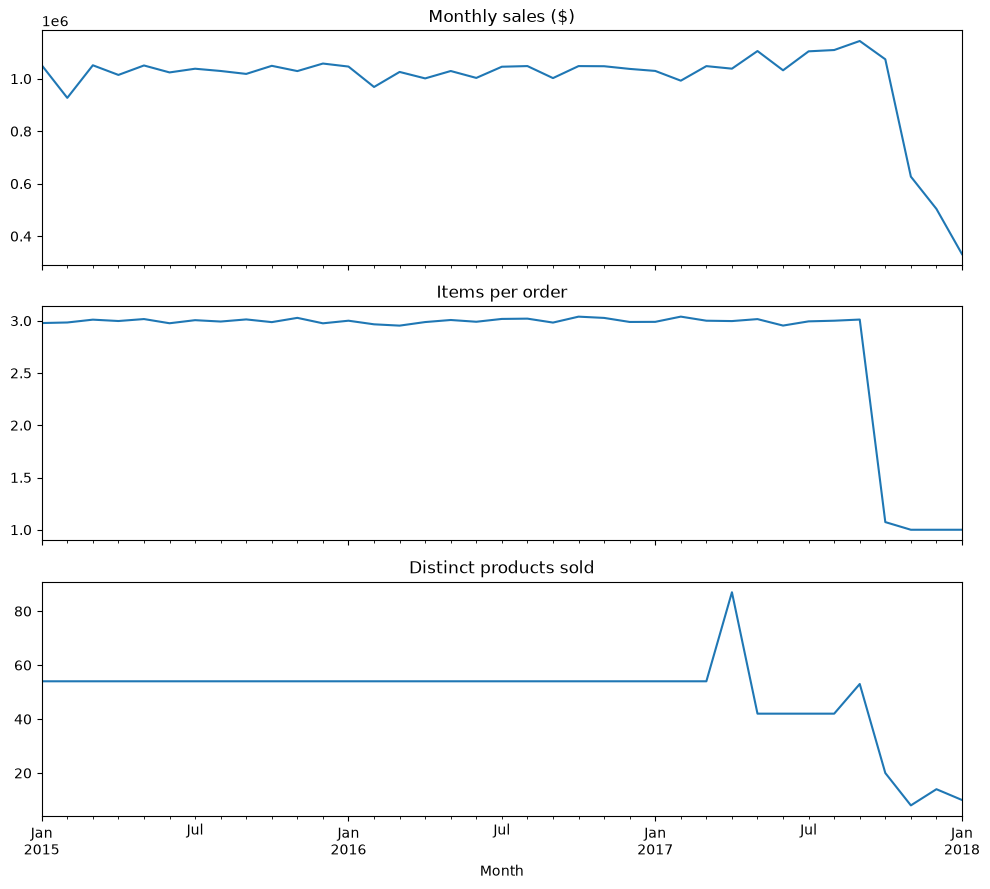

In [23]:
fig, axes = plt.subplots(3, 1, figsize=(10, 9), sharex=True)
monthly["Sales"].plot(ax=axes[0], title="Monthly sales ($)")
monthly["Items_per_Order"].plot(ax=axes[1], title="Items per order")
monthly["Products"].plot(ax=axes[2], title="Distinct products sold")
plt.tight_layout()
plt.show()

Monthly sales fall from about $1.1 million in September 2017 to about $330,000 in January 2018. The charts show this is a **change in how the data is structured, not a fall in demand**: the number of orders did not drop. For forecasting, I will train on January 2015 to September 2017 and test whether including the last four months changes the results.

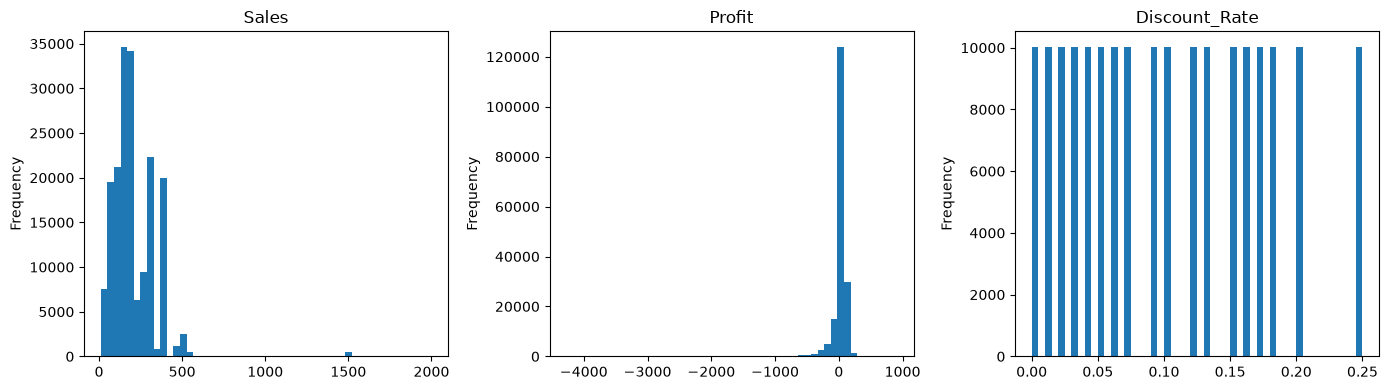

Items with profit below -$500: 1158


In [24]:
df_sql[["Sales", "Profit", "Discount_Rate"]].describe()

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ["Sales", "Profit", "Discount_Rate"]):
    df_sql[col].plot(kind="hist", bins=50, ax=ax, title=col)
plt.tight_layout()
plt.show()

print("Items with profit below -$500:", (df_sql["Profit"] < -500).sum())

## 7. Outliers
Sales are right-skewed, but the highest values (up to $2,000) are expensive products, not errors. Profit has the real outliers: the biggest loss is about -$4,275, while the biggest gain is about +$912, and about 1,158 items lose more than $500. I am **keeping** these rows, because they are real losses that drive the 18.7% loss-making rate and removing them would hide the main finding.

## 8. Summary
**Passed:** no duplicates, no shipping before ordering, shipping days verified, no invalid quantities, prices, or discounts.

**Issues found:**
1. Four columns are empty or sparse, and email and password are masked.
2. `Delivery_Status` and `Late_Delivery_Risk` are linked, which leaks the answer for modeling.
3. "Shipping canceled" combines canceled and suspected-fraud orders.
4. The data structure changes in October 2017 (1 item per order, far fewer products).
5. Profit has large negative outliers.

**Decisions:**
- Drop the empty and masked columns.
- Exclude `Delivery_Status` and real shipping days from the lateness model.
- Treat October 2017 onward separately in the forecast.
- Keep the profit outliers.